# 02 | Prepare data and source-specific histories

SUPHANATTHAKON THOBSRI | 690631023 | 270702 Data Science Programming

**Scope:** nominal-source-clock-constrained retrospective benchmark. Original historical public release/revision is not certified; operational use remains blocked. Preserve real raw data and never manufacture outcomes.


## Locate the supplied project

Open this notebook inside the extracted project, or upload its complete project ZIP when using Colab. `ROOT` is the project folder; it is not a data-source timestamp. The archive guard rejects paths outside the extraction directory.


In [1]:
from pathlib import Path  # กำหนดตำแหน่งโครงการให้ใช้ได้ในเครื่องและ Colab
import sys  # ใช้โมดูลของโครงการกับ Python ที่กำลังรัน
import os  # อ่านกุญแจจากสภาพแวดล้อมโดยไม่บันทึกค่า
import json  # อ่านค่ากำหนดและข้อมูลอธิบายที่สร้างจริง
import zipfile  # ตรวจและแตกแพ็กเกจโครงการเมื่อจำเป็น
PROJECT_NAME = 'PM25_270702_690631023_Submission'  # ระบุชื่อโครงการฝุ่นและลำดับงานสี่ขั้น
BASE = Path.cwd().resolve()  # ใช้โฟลเดอร์ที่ notebook กำลังรัน
ROOT = BASE if (BASE / 'config.json').is_file() and (BASE / 'src' / 'workflow.py').is_file() else BASE / PROJECT_NAME  # เลือกโครงการที่แตกไฟล์ไว้ก่อน
if not (ROOT / 'src' / 'workflow.py').is_file():  # ค้นหาแพ็กเกจเมื่อเปิด notebook เดี่ยวใน Colab
    if not Path('/content').is_dir():  # การรันในเครื่องต้องมีโครงการที่แตก ZIP อยู่ข้าง notebook
        raise FileNotFoundError('Extract the supplied project ZIP and open its notebook first.')  # หยุดแทนการนำเข้าโค้ดคนละโครงการ
    from google.colab import files  # ขอแพ็กเกจโค้ดและข้อมูลที่มาพร้อม notebook
    uploaded = files.upload()  # อัปโหลด ZIP โครงการที่มีข้อมูลและโค้ดครบ
    archives = [name for name in uploaded if name.lower().endswith('.zip')]  # รับเฉพาะแพ็กเกจ ZIP
    assert len(archives) == 1, 'Upload exactly one project ZIP.'  # หยุดเมื่อเลือกแพ็กเกจได้ไม่แน่นอน
    with zipfile.ZipFile(BASE / archives[0]) as archive:  # เปิด ZIP ที่เลือกเพื่อตรวจความสมบูรณ์
        assert archive.testzip() is None, 'Project ZIP is damaged.'  # ตรวจความสมบูรณ์ ZIP ก่อนแตกไฟล์
        for member in archive.infolist():  # ตรวจปลายทางทุกไฟล์แทนการเชื่อชื่อใน ZIP
            destination = (BASE / member.filename).resolve()  # หาตำแหน่งปลายทางแบบสมบูรณ์ของทุกไฟล์
            assert destination.is_relative_to(BASE), 'Unsafe archive member.'  # ปฏิเสธตำแหน่งไฟล์ที่ออกนอกโฟลเดอร์ทำงาน
        archive.extractall(BASE)  # แตกไฟล์โครงการหลังตรวจความปลอดภัย
assert (ROOT / 'src' / 'workflow.py').is_file(), 'Expected PM2.5 project not found.'  # ตรวจว่ามีโมดูลของโครงการนี้จริง
sys.path.insert(0, str(ROOT / 'src'))  # ใช้โมดูลต้นฉบับที่แนบมากับโครงการ
print('PROJECT:', ROOT)  # แสดงโครงการที่จะรันos.environ['MPLBACKEND'] = 'Agg'  # สร้างไฟล์กราฟโดยไม่เปิดหน้าต่าง
for thread_variable in ['OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS']:  # จำกัดเธรดก่อนนำเข้าไลบรารีคำนวณ
    os.environ.setdefault(thread_variable, '1')  # ใช้ค่าเริ่มต้นที่ทำซ้ำได้
os.chdir(ROOT)  # ให้ทุกพาธอ้างโครงการเดียวกัน
from common import load_config  # อ่าน contract รุ่นนี้
ROOT, CONFIG = load_config()  # ตรวจเวลาออกคำทำนายและรุ่นโครงการ
from IPython.display import display, Image, HTML  # แสดงหลักฐานและรูปภาพที่สร้างจริง
import pandas as pd  # อ่านตารางโดยรักษาบทบาทของข้อมูล
import numpy as np  # ตรวจค่าตัวเลขและลำดับเวลา
import workflow as lab  # ใช้ orchestration เดียวกับสคริปต์
from environment_check import check_environment  # ตรวจ dependency ที่ล็อกรุ่น
dependency_evidence = check_environment(ROOT, strict=True)  # ไม่เปลี่ยนรุ่นเงียบ ๆ
display(HTML("<style>.jp-CodeCell .jp-InputArea-editor,.input_area{background:#f2f2f2!important;border:1px solid #ccc}</style>"))  # รักษาพื้นเซลล์โค้ดสีเทา


PROJECT: C:\Users\User\Documents\Codex\2026-10-12\computer-assignment-2-2-string-grammar\outputs\PM25_270702_690631023_Submission


## Build the complete calendar and daily values

**Row date = history anchor D−1**, issue = D07, target date = D+1 = row date+2. P(d) is the mean/min/max of exactly 24 hourly ADS samples, from run d−1 at 12 UTC, leads 5–28; kg/m³ ×10⁹ gives µg/m³. Leads29–52 supply the provider reference for the following local day and are not predictors.

Weather uses `_previous_day1` forecast values, not ERA5 observations. Mean u/v are derived hourly as u=−s·sin(theta), v=−s·cos(theta) before aggregation; circular wind direction is not averaged arithmetically. Rain sums preceding-hour intervals assigned to interval-start day. Missing/invalid hourly values stay missing; daily values require 24 valid hours. No interpolation, forward fill, median fill or target fill is used.

GFAS retains its UTC averaging interval. At D07, the nominal latest daily start is D−2, so the fire source is aligned one day earlier than the local PM history anchor. Cell area A=R²·dλ·[sin(phi+0.05°)−sin(phi−0.05°)], R=6371008.8m. Regional mean power=Σ(FRPdensity·A)/10⁶ MW. The second fire variable is positive-analysis area/total area, not hotspot count or burnt area. `offire` is QC only and may exceed1; no clipping. Provider assimilation is distinct from project filling.


In [2]:
from prepare_data import prepare_daily, build_experiments  # ใช้การเตรียมข้อมูลเดียวกับสคริปต์
daily, join_audit = prepare_daily(ROOT, CONFIG)  # เก็บทุกวัน รวม buffer และ missing เดิม
display(daily[['date', 'issue_date', 'forecast_origin_utc', 'fire_source_day_utc', 'target_date', 'pm25_tomorrow']].head(10))  # ตรวจ offset ก่อนสร้าง lag
print(json.dumps(join_audit, indent=2))  # แสดงจำนวนแถวก่อนและหลัง join


,date,issue_date,forecast_origin_utc,fire_source_day_utc,target_date,pm25_tomorrow
0,2023-12-24,2023-12-25,2023-12-25 00:00:00+00:00,2023-12-23,2023-12-26,29.469453
1,2023-12-25,2023-12-26,2023-12-26 00:00:00+00:00,2023-12-24,2023-12-27,24.030434
2,2023-12-26,2023-12-27,2023-12-27 00:00:00+00:00,2023-12-25,2023-12-28,23.126569
3,2023-12-27,2023-12-28,2023-12-28 00:00:00+00:00,2023-12-26,2023-12-29,23.622020
4,2023-12-28,2023-12-29,2023-12-29 00:00:00+00:00,2023-12-27,2023-12-30,23.081162
5,2023-12-29,2023-12-30,2023-12-30 00:00:00+00:00,2023-12-28,2023-12-31,21.737743
6,2023-12-30,2023-12-31,2023-12-31 00:00:00+00:00,2023-12-29,2024-01-01,20.290968
7,2023-12-31,2024-01-01,2024-01-01 00:00:00+00:00,2023-12-30,2024-01-02,17.155903
8,2024-01-01,2024-01-02,2024-01-02 00:00:00+00:00,2023-12-31,2024-01-03,20.925806
9,2024-01-02,2024-01-03,2024-01-03 00:00:00+00:00,2024-01-01,2024-01-04,20.359743


{
  "pm_native_runs": 739,
  "PM_profiles": 739,
  "GFAS_utc_days": 740,
  "weather_raw_hours": 17544,
  "daily_rows_before_join": 739,
  "daily_rows_after_join": 739,
  "study_target_calendar_days": 731,
  "joins": "Unique calendar keys; PM/weather on local day; GFAS UTC day is local history anchor minus1.",
  "target_shift_calendar_days_from_anchor": 2,
  "project_predictor_fill_count": 0,
  "project_target_fill_count": 0,
  "source_advisory_policy": "Conservative all-region date-dependency quarantine; does not assert local contamination.",
  "outer_purge_target_days": [
    "2024-09-30",
    "2024-12-31"
  ]
}


## Construct exactly twelve experiments

For each base variable, feature_j = base shifted j calendar rows, j=0..k−1. PM/weather source dates are D−1−j (local), fire is D−2−j (UTC). The full calendar is retained before shifting, so missing days are never bridged. PM has3, weather7 and fire2 base variables; the maximum input table has84 columns. Metadata, labels, dates, quality flags and provider reference never enter learned feature sets.


In [3]:
X, specifications, eligible = build_experiments(ROOT, CONFIG, daily)  # สร้าง 4 กลุ่ม x 3 หน้าต่างบนวันเดียวกัน
display(pd.DataFrame([{k: v for k, v in item.items() if k != 'features'} for item in specifications]))  # แสดง input groups และจำนวนตัวแปร
display(pd.read_csv(ROOT / 'outputs/results/feature_manifest.csv'))  # นิยามตัวแปร หน่วย เหตุผล และ source day ทุกตัว
print('COMMON ELIGIBLE DAYS:', int(eligible.sum()))  # ไม่นับกริดหรือ setting ซ้ำเป็นจำนวนวัน


,id,hypothesis,window,sources,feature_count
0,H1_3d,H1,3,[PM],9
1,H1_5d,H1,5,[PM],15
2,H1_7d,H1,7,[PM],21
3,H2_3d,H2,3,"[PM, weather]",30
4,H2_5d,H2,5,"[PM, weather]",50
5,H2_7d,H2,7,"[PM, weather]",70
6,H3_3d,H3,3,"[PM, fire]",15
7,H3_5d,H3,5,"[PM, fire]",25
8,H3_7d,H3,7,"[PM, fire]",35
9,H4_3d,H4,3,"[PM, weather, fire]",36


,feature,source_group,daily_field,lag_days,unit,purpose,time_rule,publication_status
0,pm25_mean_lag0,PM,pm25_mean,0,ug/m3,Fixed-vintage mean of 24 instantaneous CAMS ho...,"Issue D07 Thai: source day D-1; fire days UTC,...",Nominal schedule constrained; actual historica...
1,pm25_mean_lag1,PM,pm25_mean,1,ug/m3,Fixed-vintage mean of 24 instantaneous CAMS ho...,"Issue D07 Thai: source day D-2; fire days UTC,...",Nominal schedule constrained; actual historica...
2,pm25_mean_lag2,PM,pm25_mean,2,ug/m3,Fixed-vintage mean of 24 instantaneous CAMS ho...,"Issue D07 Thai: source day D-3; fire days UTC,...",Nominal schedule constrained; actual historica...
3,pm25_mean_lag3,PM,pm25_mean,3,ug/m3,Fixed-vintage mean of 24 instantaneous CAMS ho...,"Issue D07 Thai: source day D-4; fire days UTC,...",Nominal schedule constrained; actual historica...
4,pm25_mean_lag4,PM,pm25_mean,4,ug/m3,Fixed-vintage mean of 24 instantaneous CAMS ho...,"Issue D07 Thai: source day D-5; fire days UTC,...",Nominal schedule constrained; actual historica...
...,...,...,...,...,...,...,...,...
79,fire_positive_area_fraction_lag2,fire,fire_positive_area_fraction,2,fraction of bounding-box grid area,Area fraction with strictly positive GFAS anal...,"Issue D07 Thai: source day D-4; fire days UTC,...",Nominal schedule constrained; actual historica...
80,fire_positive_area_fraction_lag3,fire,fire_positive_area_fraction,3,fraction of bounding-box grid area,Area fraction with strictly positive GFAS anal...,"Issue D07 Thai: source day D-5; fire days UTC,...",Nominal schedule constrained; actual historica...
81,fire_positive_area_fraction_lag4,fire,fire_positive_area_fraction,4,fraction of bounding-box grid area,Area fraction with strictly positive GFAS anal...,"Issue D07 Thai: source day D-6; fire days UTC,...",Nominal schedule constrained; actual historica...
82,fire_positive_area_fraction_lag5,fire,fire_positive_area_fraction,5,fraction of bounding-box grid area,Area fraction with strictly positive GFAS anal...,"Issue D07 Thai: source day D-7; fire days UTC,...",Nominal schedule constrained; actual historica...


COMMON ELIGIBLE DAYS: 687


## Explain every missing, retained zero and excluded day

Native GFAS zeros are retained analysis values, not project-filled days and not proof of no actual fires. Weather-history absence explains the first27 unavailable study target dates. The declared provider advisory triggers a conservative common dependency quarantine, not an assertion of local contamination. Two outer boundary target days are purged because their labels are not complete before next-stage issue/selection. Raw values remain preserved. This is separate from imputation.


In [4]:
from check_dataset import check_dataset, require_pass  # ตรวจความถูกต้องก่อนส่งเข้าโมเดล
dataset_validation = require_pass(check_dataset(ROOT, CONFIG, daily, X, specifications, eligible))  # ตรวจ shift2, source offset, lags และขอบ label
display(pd.DataFrame(dataset_validation['checks']))  # แสดงข้อจำกัด publication แยกจาก technical PASS
display(pd.read_csv(ROOT / 'outputs/results/missing_decisions.csv'))  # อธิบายทุกคอลัมน์ว่าทำไมไม่ fill และกรณีใดไม่เข้าโมเดล
display(pd.read_csv(ROOT / 'outputs/results/cohort_ledger.csv'))  # บัญชีเหตุผลแบบไม่ซ้ำนับแถว


,check,status,evidence
0,full_calendar_including_buffers,PASS,739 calendar rows; no compressed-day lagging.
1,tomorrow_after_issue_target,PASS,"History anchor =D-1; issue=D07; target=D+1, he..."
2,issue_and_target_clock,PASS,07 Thai issue; target starts17h and ends41h la...
3,target_41hour_finish,PASS,Label completion distinct from public availabi...
4,unknown_targets_never_safe_labels,PASS,Unknown labels retain NA.
5,all_declared_calendar_lags,PASS,84 exact columns; metadata and provider refere...
6,all_twelve_exact_feature_contracts,PASS,Every source/lag set independently reconstructed.
7,shared_cohort_exact,PASS,Same max-window source/date eligibility for al...
8,row_ledger_retention_matches_eligibility,PASS,"No excluded row may be labelled retained, incl..."
9,minimum_500_common_days,PASS,687


,column,missing_rows,missing_percent,action,reason
0,date,0,0.000000,Retain audit identity/QC; exclude it from lear...,"History anchor D-1; calendar join key, not a p..."
1,pm25_mean,0,0.000000,No imputation; preserve missing and require co...,Avoid invented history or target-dependent eli...
2,pm25_min,0,0.000000,No imputation; preserve missing and require co...,Avoid invented history or target-dependent eli...
3,pm25_max,0,0.000000,No imputation; preserve missing and require co...,Avoid invented history or target-dependent eli...
4,pm25_valid_hours,0,0.000000,Retain audit identity/QC; exclude it from lear...,Number of valid PM samples; 24 required.
5,temperature_mean,27,3.653586,No imputation; preserve missing and require co...,Avoid invented history or target-dependent eli...
6,humidity_mean,27,3.653586,No imputation; preserve missing and require co...,Avoid invented history or target-dependent eli...
7,pressure_mean,27,3.653586,No imputation; preserve missing and require co...,Avoid invented history or target-dependent eli...
8,wind_speed_ms,27,3.653586,No imputation; preserve missing and require co...,Avoid invented history or target-dependent eli...
9,wind_u_ms,27,3.653586,No imputation; preserve missing and require co...,Avoid invented history or target-dependent eli...


,status,rows
0,retained_common,687
1,invalid_or_missing_input_history,27
2,conservative_source_advisory_dependency,15
3,outer_label_maturity_purge,2


## Separate partitions, answers and audit database

Train ends29Sep 2024; validation1Oct–30Dec 2024; test is full 2025. Target30Sep/31Dec 2024 are maturity purges. This gives a full-season test without tuning cutoffs to new scores. All folds use calendar gaps and explicit target completion timestamps. Scaling stays inside each Ridge CV fold. A shared SQLite audit store copies real records; it is neither a fabricated reference dataset nor another predictor. Test features contain no answers.


In [5]:
from stages import prepare_handoff  # ใช้ shared orchestration เพื่อไม่ให้ notebook และ script ต่างกัน
handoff = prepare_handoff(ROOT, CONFIG, daily, X, specifications, eligible)  # ตรวจข้อมูล ส่งออก answers แยก และสร้าง SQL store
display(pd.read_csv(ROOT / 'outputs/results/chronology.csv'))  # แสดงวันและจำนวนแต่ละ partition
display(pd.read_csv(ROOT / 'outputs/results/cv_calendar_audit.csv'))  # ตรวจ label maturity ภายในแต่ละ fold
print('SQL STORE:', handoff['reference']['status'])  # ฐานข้อมูลใช้ตรวจหลักฐานจริง ไม่ใช่สร้าง target ใหม่


,partition,n,first_target,last_target,first_issue_utc,last_label_complete_utc,positive_days
0,train,231,2024-01-28 00:00:00,2024-09-29 00:00:00,2024-01-27 00:00:00+00:00,2024-09-29 17:00:00+00:00,7
1,validation,91,2024-10-01 00:00:00,2024-12-30 00:00:00,2024-09-30 00:00:00+00:00,2024-12-30 17:00:00+00:00,3
2,test,365,2025-01-01 00:00:00,2025-12-31 00:00:00,2024-12-31 00:00:00+00:00,2025-12-31 17:00:00+00:00,30


,fold,train_rows,validation_rows,last_train_target,first_validation_target,last_train_label_complete_utc,first_validation_issue_utc,gap_calendar_days,label_maturity_pass,publication_check
0,1,41,68,2024-03-08 00:00:00,2024-03-10 00:00:00,2024-03-08 17:00:00+00:00,2024-03-09 00:00:00+00:00,1,True,Nominal source-clock benchmark; original publi...
1,2,109,68,2024-05-15 00:00:00,2024-05-17 00:00:00,2024-05-15 17:00:00+00:00,2024-05-16 00:00:00+00:00,1,True,Nominal source-clock benchmark; original publi...
2,3,177,53,2024-07-22 00:00:00,2024-07-24 00:00:00,2024-07-22 17:00:00+00:00,2024-07-23 00:00:00+00:00,1,True,Nominal source-clock benchmark; original publi...


SQL STORE: PASS


## Inspect coverage and handoff evidence

Every target date remains in the inclusion ledger, with one first-failure reason, including a missing direct-provider reference; excluded rows cannot be labelled retained. Feature availability records deliberately distinguish nominal admissibility from verified original release. Nothing in this cell changes masks or parameters using test performance.

Temporal cutoff checks are reported separately from UNVERIFIED exact historical public-release evidence. The daily-variable dictionary specifies units and roles for targets, baselines, counts, flags and dates as well as predictors.


,date,target_date,first_window_complete,in_study_target_calendar,all_input_values_present,target_present,provider_reference_present,values_complete,source_advisory_dependency,outer_label_purge,eligible_common,first_failure
727,2025-12-20,2025-12-22,True,True,True,True,True,True,False,False,True,retained_common
728,2025-12-21,2025-12-23,True,True,True,True,True,True,False,False,True,retained_common
729,2025-12-22,2025-12-24,True,True,True,True,True,True,False,False,True,retained_common
730,2025-12-23,2025-12-25,True,True,True,True,True,True,False,False,True,retained_common
731,2025-12-24,2025-12-26,True,True,True,True,True,True,False,False,True,retained_common
732,2025-12-25,2025-12-27,True,True,True,True,True,True,False,False,True,retained_common
733,2025-12-26,2025-12-28,True,True,True,True,True,True,False,False,True,retained_common
734,2025-12-27,2025-12-29,True,True,True,True,True,True,False,False,True,retained_common
735,2025-12-28,2025-12-30,True,True,True,True,True,True,False,False,True,retained_common
736,2025-12-29,2025-12-31,True,True,True,True,True,True,False,False,True,retained_common


,feature,source_group,availability_status,nominal_schedule_admissible,documented_latency_conflict,operational_use_allowed,valid_date_rule,historical_available_at,evidence_context
0,pm25_mean_lag0,PM,UNVERIFIED,True,False,False,"Issue D07 Thai: source day D-1; fire days UTC,...",NaN,Actual native forecast/analysis identity plus ...
1,pm25_mean_lag1,PM,UNVERIFIED,True,False,False,"Issue D07 Thai: source day D-2; fire days UTC,...",NaN,Actual native forecast/analysis identity plus ...
2,pm25_mean_lag2,PM,UNVERIFIED,True,False,False,"Issue D07 Thai: source day D-3; fire days UTC,...",NaN,Actual native forecast/analysis identity plus ...
3,pm25_mean_lag3,PM,UNVERIFIED,True,False,False,"Issue D07 Thai: source day D-4; fire days UTC,...",NaN,Actual native forecast/analysis identity plus ...
4,pm25_mean_lag4,PM,UNVERIFIED,True,False,False,"Issue D07 Thai: source day D-5; fire days UTC,...",NaN,Actual native forecast/analysis identity plus ...
...,...,...,...,...,...,...,...,...,...
80,fire_positive_area_fraction_lag3,fire,UNVERIFIED,True,False,False,"Issue D07 Thai: source day D-5; fire days UTC,...",NaN,Actual native forecast/analysis identity plus ...
81,fire_positive_area_fraction_lag4,fire,UNVERIFIED,True,False,False,"Issue D07 Thai: source day D-6; fire days UTC,...",NaN,Actual native forecast/analysis identity plus ...
82,fire_positive_area_fraction_lag5,fire,UNVERIFIED,True,False,False,"Issue D07 Thai: source day D-7; fire days UTC,...",NaN,Actual native forecast/analysis identity plus ...
83,fire_positive_area_fraction_lag6,fire,UNVERIFIED,True,False,False,"Issue D07 Thai: source day D-8; fire days UTC,...",NaN,Actual native forecast/analysis identity plus ...


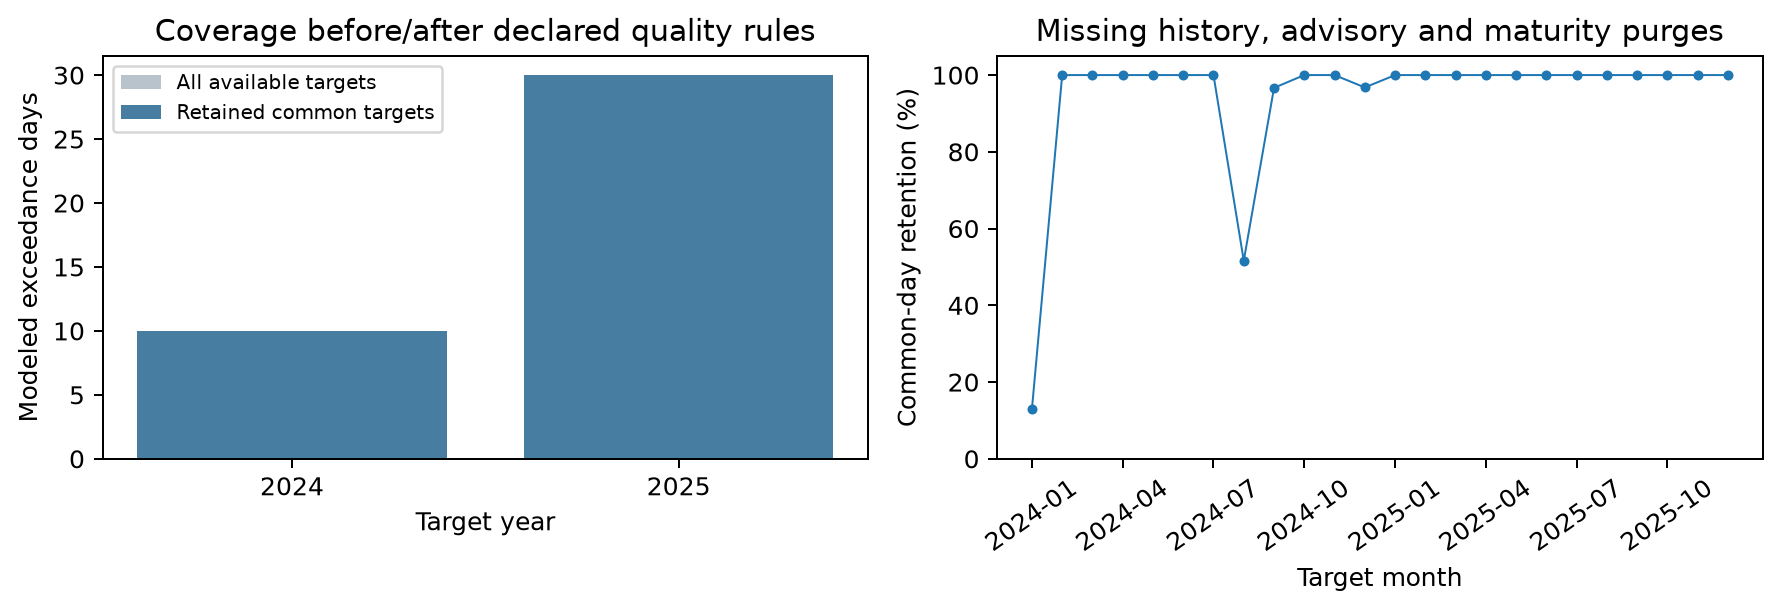

In [6]:
display(pd.read_csv(ROOT / 'outputs/results/row_inclusion.csv').tail(12))  # คงแถวที่ไม่ใช้ให้ตรวจเหตุผลได้
display(pd.read_csv(ROOT / 'outputs/results/feature_availability.csv'))  # แสดงสถานะ UNVERIFIED ของ original release ตามจริง
display(Image(filename=str(ROOT / 'outputs/figures/06_matched_period_coverage.png'), width=900))  # แสดงผลการคัดวันร่วมและความเป็นตัวแทน
